# MCDI505 · Formativa 4 — Informe ejecutivo del proyecto

| | |
|---|---|
| **Estudiante** | Claudio Rodolfo Alarcón Pradenas |
| **Docente** | Dr. Harvey Jezlid Rosas Quintero |
| **Evaluación** | Formativa 4 · Semana 4 · Fase 4 — Presentación y comunicación del proyecto |
| **Archivo** | `mcdi505_S4calarcon.ipynb` |
| **Datos** | `data/raw/consumo_electrico_litoral_depurado.csv` |
| **Repositorio (respaldo y reproducibilidad)** | `https://github.com/claudioalarconP/Analisis_de_serie_de_tiempo` |

**Pregunta de la semana:** ¿Qué consumo espera DEL para los próximos 12 meses, con qué incertidumbre y qué volumen debería contratar?

**Problema y enfoque.** DEL compromete cada diciembre la energía comercial de los 12 meses siguientes: contratar de menos obliga a comprar después a mayor precio y contratar de más paga energía que no se usa (Universidad Andrés Bello [UNAB], s. f.-a). Se evalúa una sola vez en 2024 el modelo elegido en las Semanas 2 y 3, se compara con el naive estacional y el resultado se traduce en un criterio de contratación.

## Hoja de decisiones

Punto de partida: **M4 = SARIMA(0,1,0)(1,1,0)₁₂** sobre log(consumo), sin variables exógenas, seleccionado en la Sumativa 2 y ratificado en la Sumativa 3. Se reestima con 2015-01 a 2023-12 y se evalúa una sola vez en 2024.

| Criterio | Decisión o conclusión | Evidencia clave (cifra, prueba o figura) | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Modelo de partida | Se mantiene M4 = SARIMA(0,1,0)(1,1,0)₁₂ sobre log(consumo), sin exógenas. | S3: RMSE / MAE 2023 = 4,12 / 3,71 GWh; ARFIMA no mejora (4,19 / 3,75); GARCH sin mejora sustantiva (ancho 45,64 frente a 46,26 GWh); 9 de 12 meses de 2023 subestimados; rezago 24 aislado (−0,35). | M4 + ARFIMA(0,d,0) y M4 + bandas GARCH(1,1) | Pasa a la S4 sin cambios (`D_FRACCIONAL = None`, `BANDAS_GARCH = False`). |
| 2. Reestimación 2015–2023 | Mismos órdenes; modelo congelado antes de abrir 2024. | n = 108; Φ1 = −0,359 (ee = 0,094) frente a −0,311 en la S3: 0,5 errores estándar; converge (Tabla 1). | Reespecificar con la información de 2023 | Sin evidencia suficiente de cambio estructural a partir de esta diferencia de parámetros. |
| 3. Prueba 2024 | 2024 se abre una sola vez, solo para evaluar. | RMSE = 5,35 y MAE = 4,65 GWh; alterar 2024 no cambia los parámetros (Tabla 3, Fig. 1). | Reestimar con 2024 antes de evaluar | Evaluación fuera de muestra válida. |
| 4. Naive y MASE | M4 supera al naive estacional. | MASE = 0,71 frente a 1,02; RMSE −34,7 % y MAE −30,3 % (Tabla 3). | Naive estacional como pronóstico | Se mantiene M4. |
| 5. Cobertura | Compatible con un IC al 95 %, sin probar su calibración. | 12/12 meses dentro; ancho medio 50,70 GWh; con un IC calibrado, P(12 de 12) = 0,54. | Afirmar que el IC garantiza la cobertura | El IC dimensiona la incertidumbre. |
| 6. Sesgo 2024 (retroalimentación S3) | La subestimación de 2023 cambia de signo. | 2023: ME = +3,21 GWh, 9/12 subestimados. 2024: ME = −2,92 GWh, 10/12 sobrestimados, +2,4 % anual (Tabla 4). | Corregir el nivel con el error de 2024 | Se declara como limitación; reestimar cada diciembre. |
| 7. Contratación | Contratar mes a mes un cuantil τ* = c_u / (c_u + c_o) > 0,5, por sobre la mediana. | c_u > c_o (caso transversal, sección 3); c_u y c_o numéricos no disponibles: τ* no calculable (Anexo, Tabla 6). | Contratar el pronóstico medio | Falta que DEL cuantifique la razón de costos. |
| 8. Limitaciones | Alcance: esta serie y un año de prueba. | 12 meses de prueba; COVID-19 en el ajuste; ρ24 = −0,31; cambio de signo del sesgo (§7). | Generalizar el resultado de 2024 | Afectan la confianza, no la elección de M4. |

## 0. Reproducibilidad y datos

Serie mensual `consumo_gwh` (2015-01 a 2024-12) del CSV depurado, cargada con rutas relativas, semilla 505 y las funciones de la plantilla oficial sin modificaciones (UNAB, s. f.-b). Partición: **2015–2023** para reestimar (108 meses) y **2024** como prueba final (12 meses), que solo se abre en la §3.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
warnings.filterwarnings("ignore")
SEMILLA = 505
np.random.seed(SEMILLA)

# Agregados respecto de la plantilla (los mismos de la Sumativa 3, más los de la Semana 4)
import hashlib, platform, json
from pathlib import Path
import scipy, statsmodels, matplotlib
from scipy.stats import norm, binom
from IPython.display import display
from statsmodels.tsa.stattools import acf

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
                     "axes.titlesize": 11, "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False})
ROJO, AZUL, GRIS, VERDE, NARANJA = "#b30338", "#0057b8", "#9e9e9e", "#2e7d32", "#ef6c00"
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
      f"statsmodels {statsmodels.__version__} | matplotlib {matplotlib.__version__} | semilla = {SEMILLA}")

# ==============================================================================
# Funciones de apoyo (las mismas de la Sesión 3, más tres envoltorios para DEL)
# ==============================================================================

def calcular_exponente_hurst(serie, min_ventana=8, max_ventana=None, n_ventanas=10):
    """Exponente de Hurst por Rango Reescalado (R/S). Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    if max_ventana is None:
        max_ventana = n // 4
    ventanas = np.unique(np.geomspace(min_ventana, max_ventana, num=n_ventanas, dtype=int))
    rs_promedio, ventanas_validas = [], []
    for w in ventanas:
        m = n // w
        if m < 1:
            continue
        rs_bloques = []
        for i in range(m):
            bloque = serie[i * w:(i + 1) * w]
            recorrido = np.cumsum(bloque - np.mean(bloque))
            desviacion = np.std(bloque)
            if desviacion > 0:
                rs_bloques.append((np.max(recorrido) - np.min(recorrido)) / desviacion)
        if rs_bloques:
            rs_promedio.append(np.mean(rs_bloques))
            ventanas_validas.append(w)
    pendiente, _ = np.polyfit(np.log(ventanas_validas), np.log(rs_promedio), 1)
    return pendiente


def aplicar_filtro_fraccional(serie, d):
    """Operador (1-B)^d. d > 0 diferencia fraccionalmente; d < 0 integra. Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    pesos = np.zeros(n)
    pesos[0] = 1.0
    for k in range(1, n):
        pesos[k] = pesos[k - 1] * (k - 1 - d) / k
    return np.array([np.sum(pesos[:t + 1] * serie[t::-1]) for t in range(n)])


def garch_log_verosimilitud_negativa(parametros, serie):
    """Log-verosimilitud negativa de un GARCH(1,1) gaussiano. Ver Sesión 3, §3.4."""
    omega, alpha, beta = parametros
    sigma2 = np.zeros(len(serie))
    sigma2[0] = np.var(serie)
    for t in range(1, len(serie)):
        sigma2[t] = omega + alpha * serie[t - 1] ** 2 + beta * sigma2[t - 1]
    if np.any(sigma2 <= 1e-8):
        return 1e10
    return 0.5 * np.sum(np.log(2 * np.pi) + np.log(sigma2) + serie ** 2 / sigma2)


def correccion_arfima(residuos, d, h):
    """Pronóstico h pasos del componente ARFIMA(0,d,0) de los residuos.

    Diferencia fraccionalmente los residuos con d, pronostica cero (ruido blanco)
    y vuelve a integrar con -d. Lo que queda es la persistencia que la memoria
    larga añadiría al pronóstico del SARIMA (en escala logarítmica).
    """
    r = np.asarray(residuos, dtype=float)
    extendida = np.concatenate([aplicar_filtro_fraccional(r, d), np.zeros(h)])
    return aplicar_filtro_fraccional(extendida, -d)[len(r):]


def estimar_garch11(residuos, h):
    """Estima un GARCH(1,1) por MLE sobre los residuos estandarizados.

    Devuelve un diccionario con omega, alpha, beta, persistencia, convergencia,
    residuos estandarizados por sigma_t y el factor de escala de la desviación
    estándar condicional para los h meses siguientes (1 = igual a la varianza
    incondicional).
    """
    r = np.asarray(residuos, dtype=float)
    s = r.std()
    u = r / s
    res = minimize(garch_log_verosimilitud_negativa, x0=[0.05, 0.10, 0.80], args=(u,),
                   bounds=[(1e-6, 5.0), (1e-6, 0.999), (1e-6, 0.999)],
                   constraints=({"type": "ineq", "fun": lambda p: 0.999 - p[1] - p[2]},),
                   method="SLSQP")
    om, al, be = res.x
    sigma2 = np.zeros(len(u)); sigma2[0] = u.var()
    for t in range(1, len(u)):
        sigma2[t] = om + al * u[t - 1] ** 2 + be * sigma2[t - 1]
    futura = np.zeros(h)
    futura[0] = om + al * u[-1] ** 2 + be * sigma2[-1]
    for i in range(1, h):
        futura[i] = om + (al + be) * futura[i - 1]
    incondicional = om / (1 - al - be)
    return {"omega": om, "alpha": al, "beta": be, "persistencia": al + be,
            "convergencia": bool(res.success),
            "residuos_estandarizados": u / np.sqrt(sigma2),
            "escala_futura": np.sqrt(futura / incondicional)}


def metricas(real, pred):
    """RMSE y MAE en la escala de los datos (GWh)."""
    e = np.asarray(real, float) - np.asarray(pred, float)
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e)))}


def cobertura_y_ancho(real, inferior, superior):
    """Proporción de meses dentro del intervalo y ancho promedio del intervalo (GWh)."""
    real, inferior, superior = (np.asarray(x, float) for x in (real, inferior, superior))
    return {"Cobertura": float(np.mean((real >= inferior) & (real <= superior))),
            "Ancho medio": float(np.mean(superior - inferior))}

Python 3.12.5 | numpy 2.4.6 | pandas 3.0.3 | scipy 1.18.0 | statsmodels 0.14.6 | matplotlib 3.10.9 | semilla = 505


In [2]:
# Celda de carga de la plantilla con rutas relativas (como en las Sumativas 2 y 3)
ARCHIVO = "consumo_electrico_litoral_depurado.csv"
rutas = [Path(*[".."] * n) / sub / ARCHIVO for n in range(5) for sub in (".", "data", "data/raw", "data/processed")]
ruta = next((r for r in rutas if r.exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No se encontró {ARCHIVO}: ubíquelo junto al notebook o en data/, data/raw o data/processed.")
df = pd.read_csv(ruta, parse_dates=["fecha"], index_col="fecha")
df.index.freq = "MS"
y = df["consumo_gwh"]
log_y = np.log(y)

# Validación de la serie (sin inspeccionar los valores de 2024) y partición final
SHA_S3 = "d308b3605bf47ed8"                                     # huella del CSV informada en la Sumativa 3
sha_csv = hashlib.sha256(ruta.read_bytes()).hexdigest()
assert len(y) == 120 and y.index.equals(pd.date_range("2015-01-01", "2024-12-01", freq="MS")) and y.index.freqstr == "MS"
assert y.index.is_monotonic_increasing and not y.index.duplicated().any() and y.notna().all() and (y > 0).all()
assert sha_csv.startswith(SHA_S3), "el CSV no es el mismo de la Sumativa 3"
train_final, test_final = y[:"2023-12"], y["2024-01":"2024-12"]
assert len(train_final) == 108 and train_final.index[-1] == pd.Timestamp("2023-12-01")
assert len(test_final) == 12 and test_final.index[0] == pd.Timestamp("2024-01-01") and train_final.index.intersection(test_final.index).empty

CARPETA_FIG = ruta.parent.parent.parent / "resultados" / "semana_4" / "S4" if ruta.parent.name == "raw" else Path("figuras_s4")
CARPETA_FIG.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    fig.savefig(CARPETA_FIG / nombre, dpi=200, bbox_inches="tight")

print(f"{ruta.as_posix()} | {len(y)} meses ({y.index[0]:%Y-%m} a {y.index[-1]:%Y-%m}) | frecuencia {y.index.freqstr} | "
      f"duplicados = 0 | faltantes = 0 | SHA-256 {sha_csv[:16]}… (S3: {SHA_S3}…)")
print(f"train_final: {train_final.index[0]:%Y-%m} a {train_final.index[-1]:%Y-%m} ({len(train_final)}) | "
      f"test_final: {test_final.index[0]:%Y-%m} a {test_final.index[-1]:%Y-%m} ({len(test_final)})")

../../../data/raw/consumo_electrico_litoral_depurado.csv | 120 meses (2015-01 a 2024-12) | frecuencia MS | duplicados = 0 | faltantes = 0 | SHA-256 d308b3605bf47ed8… (S3: d308b3605bf47ed8…)
train_final: 2015-01 a 2023-12 (108) | test_final: 2024-01 a 2024-12 (12)


## 1. Modelo heredado de la Sumativa 3

M4 = SARIMA(0,1,0)(1,1,0)₁₂ sobre log(consumo), sin exógenas: seleccionado en la Sumativa 2 por su menor error en la validación 2023 y ratificado en la Sumativa 3, donde ARFIMA (H = 0,584) y GARCH (ARCH-LM p = 0,786) no aportaron. Se completa la especificación de la plantilla sin componentes avanzados y se verifica que M4 reproduce las cifras de la S3. Punto a vigilar (retroalimentación S3): la subestimación de 2023, 9 de 12 meses.

In [ ]:
# ==============================================================================
# Modelo SARIMA seleccionado en la Sumativa 2 y ratificado en la Sumativa 3
# ==============================================================================
ORDEN = (0, 1, 0)              # M4: seleccionado en la Sumativa 2 y ratificado en la Sumativa 3
ORDEN_ESTACIONAL = (1, 1, 0, 12)
USAR_COVID = False        # M4 no lleva variables exógenas

assert ORDEN is not None and ORDEN_ESTACIONAL is not None, "Complete ORDEN y ORDEN_ESTACIONAL con su modelo de la Sumativa 2."

# COMPLETE solo si en la Sumativa 3 su modelo final incorporó componentes avanzados
D_FRACCIONAL = None       # la S3 concluyó que ARFIMA(0,d,0) no aporta
BANDAS_GARCH = False      # la S3 concluyó que GARCH(1,1) no aporta
assert (ORDEN, ORDEN_ESTACIONAL, USAR_COVID, D_FRACCIONAL, BANDAS_GARCH) == ((0, 1, 0), (1, 1, 0, 12), False, None, False)
MODELO = "SARIMA M4"

def ajustar_y_pronosticar(fin_entrenamiento, inicio_prueba, fin_prueba):
    """Ajusta el modelo final hasta `fin_entrenamiento` y pronostica el periodo de prueba en GWh."""
    lt = log_y[:fin_entrenamiento]
    h = len(log_y[inicio_prueba:fin_prueba])
    Xt = df[["covid"]][:fin_entrenamiento] if USAR_COVID else None
    Xp = df[["covid"]].loc[inicio_prueba:fin_prueba] if USAR_COVID else None
    m = SARIMAX(lt, exog=Xt, order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
    inicio = ORDEN[1] + ORDEN_ESTACIONAL[1] * ORDEN_ESTACIONAL[3]
    resid = m.resid.iloc[inicio:]
    p = m.get_forecast(h, exog=Xp)
    media = p.predicted_mean.to_numpy()
    sd = ((p.conf_int(alpha=0.05).iloc[:, 1] - p.predicted_mean) / 1.96).to_numpy()
    if D_FRACCIONAL is not None:
        media = media + correccion_arfima(resid, D_FRACCIONAL, h)
    if BANDAS_GARCH:
        sd = sd * estimar_garch11(resid, h)["escala_futura"]
    return np.exp(media), np.exp(media - 1.96 * sd), np.exp(media + 1.96 * sd)


def evaluar(fin_entrenamiento, inicio_prueba, fin_prueba):
    """Métricas del modelo final y del naive estacional sobre el periodo de prueba."""
    real = y[inicio_prueba:fin_prueba].to_numpy()
    pred, inf, sup = ajustar_y_pronosticar(fin_entrenamiento, inicio_prueba, fin_prueba)
    naive = y.shift(12)[inicio_prueba:fin_prueba].to_numpy()
    y_ent = y[:fin_entrenamiento]
    escala_mase = float((y_ent - y_ent.shift(12)).dropna().abs().mean())   # MAE del naive estacional en entrenamiento
    filas = {}
    for nombre, p in [("Modelo final", pred), ("Naive estacional", naive)]:
        m = metricas(real, p)
        m["MASE"] = float(np.mean(np.abs(real - p)) / escala_mase)
        filas[nombre] = m
    tabla = pd.DataFrame(filas).T
    tabla["Cobertura IC 95 %"] = [cobertura_y_ancho(real, inf, sup)["Cobertura"], np.nan]
    return tabla, pred, inf, sup


# Cifras heredadas de la Sumativa 3 (recuperadas de sus salidas; no se recalculan para las tablas)
S3 = {"phi": -0.311, "sigma2": 0.00193, "aic": -277.8, "n": 96, "rmse": 4.12, "mae": 3.71, "me": 3.21, "subestimados": 9,
      "cobertura": 12, "total_pron": 1325.4, "dif_pct": -2.8, "rmse_naive": 7.26, "mae_naive": 6.53, "me_naive": 6.53}

# Control de continuidad: M4 con 2015-2022 y media exp(m + s²/2), como en la S3, reproduce las cifras heredadas
ajuste_s3 = SARIMAX(log_y[:"2022-12"], order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False, maxiter=200)
p_s3 = ajuste_s3.get_forecast(12)
sd_s3 = (p_s3.conf_int(alpha=0.05).iloc[:, 1] - p_s3.predicted_mean) / 1.96
media_s3 = np.exp(p_s3.predicted_mean + sd_s3 ** 2 / 2).to_numpy()
inf_s3, sup_s3 = np.exp(p_s3.predicted_mean - 1.96 * sd_s3).to_numpy(), np.exp(p_s3.predicted_mean + 1.96 * sd_s3).to_numpy()
real_2023 = y["2023-01":"2023-12"].to_numpy()
e_s3, met_s3 = real_2023 - media_s3, metricas(real_2023, media_s3)
continuidad = {
    "Φ1": round(ajuste_s3.params["ar.S.L12"], 3) == S3["phi"],
    "RMSE y MAE 2023": round(met_s3["RMSE"], 2) == S3["rmse"] and round(met_s3["MAE"], 2) == S3["mae"],
    "ME y meses subestimados": round(e_s3.mean(), 2) == S3["me"] and (e_s3 > 0).sum() == S3["subestimados"],
    "energía 2023": round(media_s3.sum(), 1) == S3["total_pron"] and round(100 * (media_s3.sum() / real_2023.sum() - 1), 1) == S3["dif_pct"],
    "cobertura 12/12": int(((real_2023 >= inf_s3) & (real_2023 <= sup_s3)).sum()) == S3["cobertura"],
}
assert all(continuidad.values()), "M4 no reproduce la Sumativa 3"
print(f"[OK] M4 reproduce la S3: Φ1 = {ajuste_s3.params['ar.S.L12']:.3f} | RMSE / MAE 2023 = {met_s3['RMSE']:.2f} / {met_s3['MAE']:.2f} GWh | "
      f"ME = {e_s3.mean():+.2f} GWh | subestimados = {(e_s3 > 0).sum()}/12 | energía {100 * (media_s3.sum() / real_2023.sum() - 1):+.1f} % | cobertura 12/12")

[OK] M4 reproduce la S3: Φ1 = -0.311 | RMSE / MAE 2023 = 4.12 / 3.71 GWh | ME = +3.21 GWh | subestimados = 9/12 | energía -2.8 % | cobertura 12/12


## 2. Reestimación 2015–2023 y pronóstico 2024

M4 se reestima con 2015-01 a 2023-12 con la llamada de la plantilla (Seabold y Perktold, 2010). Especificación, parámetros y pronóstico 2024 quedan congelados, con una huella numérica, antes de abrir la prueba; también se revisan los residuos del modelo reestimado.

In [4]:
modelo_final = SARIMAX(np.log(train_final), order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
assert modelo_final.mle_retvals.get("converged", True) and modelo_final.nobs == 108
assert modelo_final.fittedvalues.index.max() == pd.Timestamp("2023-12-01") and modelo_final.model.k_exog == 0

# Sello: alterar los valores de 2024 no cambia el ajuste
log_alterada = log_y.copy()
log_alterada["2024-01":"2024-12"] = 0.0
SELLO_2024 = bool(np.allclose(SARIMAX(log_alterada[:"2023-12"], order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False).params,
                              modelo_final.params, rtol=0, atol=1e-12))
assert SELLO_2024

# Congelamiento del pronóstico 2024 (escala log) antes de leer los valores reales
p24 = modelo_final.get_forecast(12)
m24 = p24.predicted_mean
sd24 = (p24.conf_int(alpha=0.05).iloc[:, 1] - m24) / 1.96
def huella(*arreglos):
    return hashlib.sha256(np.concatenate([np.asarray(a, float).ravel() for a in arreglos]).round(12).tobytes()).hexdigest()[:16]
CONGELADO = {"parametros": modelo_final.params.copy(), "m": m24.copy(), "sd": sd24.copy()}
HUELLA_CONGELADO = huella(CONGELADO["parametros"], CONGELADO["m"], CONGELADO["sd"])

phi_s4, se_phi, sigma2_s4 = modelo_final.params["ar.S.L12"], modelo_final.bse["ar.S.L12"], modelo_final.params["sigma2"]
tabla_reest = pd.DataFrame({
    "Sumativa 3 (2015-2022)": [str(S3["n"]), f"{S3['phi']:.3f}", "—", f"{S3['sigma2']:.5f}", f"{S3['aic']:.1f}", "sí"],
    "Sumativa 4 (2015-2023)": [str(modelo_final.nobs), f"{phi_s4:.3f}", f"{se_phi:.3f}", f"{sigma2_s4:.5f}", f"{modelo_final.aic:.1f}",
                               "sí" if modelo_final.mle_retvals.get("converged", True) else "no"]},
    index=["n", "Φ1", "error estándar de Φ1", "σ²", "AIC", "converge"])
display(tabla_reest.style.set_caption("Tabla 1. Reestimación de M4 = SARIMA(0,1,0)(1,1,0)12 sobre log(consumo)"))

pron24 = pd.DataFrame({"Pronóstico (mediana exp(m))": np.exp(m24), "IC 95 % inferior": np.exp(m24 - 1.96 * sd24),
                       "IC 95 % superior": np.exp(m24 + 1.96 * sd24)})
pron24.index = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
display(pron24.T.style.format("{:.1f}", decimal=",").set_caption("Tabla 2. Pronóstico 2024 de M4 (GWh), congelado antes de abrir la prueba"))

# Residuos del modelo reestimado (se descartan los primeros d + D·s = 13, como en la S3)
inicio = ORDEN[1] + ORDEN_ESTACIONAL[1] * ORDEN_ESTACIONAL[3]
res_final = modelo_final.resid.iloc[inicio:]
acf_final = acf(res_final, nlags=36)
banda_final = 1.96 / np.sqrt(len(res_final))
lb_final = acorr_ljungbox(res_final, lags=[12, 24], model_df=1)
z_final = (res_final / res_final.std()).abs()
print(f"ΔΦ1 (S4 − S3) = {phi_s4 - S3['phi']:+.3f} = {abs(phi_s4 - S3['phi']) / se_phi:.1f} ee | [OK] 2024 no participa en el ajuste | "
      f"[OK] modelo congelado: huella {HUELLA_CONGELADO}")
print(f"Residuos (n = {len(res_final)}): fuera de ±{banda_final:.3f}: {[k for k in range(1, 37) if abs(acf_final[k]) > banda_final]} "
      f"(ρ24 = {acf_final[24]:.2f}) | Ljung-Box p (K = 12 / 24) = {lb_final.lb_pvalue.iloc[0]:.3f} / {lb_final.lb_pvalue.iloc[1]:.3f} | "
      f"mayor residuo: {z_final.idxmax():%Y-%m} ({z_final.max():.1f} s)")

,Sumativa 3 (2015-2022),Sumativa 4 (2015-2023)
n,96,108
Φ1,-0.311,-0.359
error estándar de Φ1,—,0.094
σ²,0.00193,0.00184
AIC,-277.8,-322.9
converge,sí,sí


,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
Pronóstico (mediana exp(m)),"141,7","129,5","123,5","109,6","113,8","118,2","120,3","117,4","114,9","114,8","128,9","143,2"
IC 95 % inferior,"130,3","114,9","106,7","92,6","94,3","96,1","96,3","92,6","89,2","88,0","97,5","107,0"
IC 95 % superior,"154,1","145,8","142,8","129,7","137,3","145,2","150,3","149,0","147,8","149,7","170,4","191,7"


ΔΦ1 (S4 − S3) = -0.048 = 0.5 ee | [OK] 2024 no participa en el ajuste | [OK] modelo congelado: huella 71afb4a7e78fa403
Residuos (n = 95): fuera de ±0.201: [24] (ρ24 = -0.31) | Ljung-Box p (K = 12 / 24) = 0.637 / 0.185 | mayor residuo: 2020-04 (3.4 s)


Φ1 pasa de −0,311 a −0,359 (0,5 errores estándar): variación esperable al agregar un año, no un cambio estructural. El AIC (−322,9) no es comparable con el de la S3 porque la muestra es distinta. En los residuos solo el rezago 24 sale de la banda (ρ24 = −0,31), y Ljung-Box en K = 24 no rechaza (p = 0,185).

## 3. Evaluación final 2024

Se abre 2024 una sola vez con `evaluar` de la plantilla y se compara M4 con el naive estacional (mismo mes del año anterior) mediante RMSE, MAE, MASE (escala: MAE del naive estacional en entrenamiento; Hyndman y Koehler, 2006), ME = promedio(real − pronóstico) y cobertura del IC 95 %. Las filas de 2023 con la media corregida provienen de la S3.

[OK] 2024 no participa en el ajuste | [OK] modelo congelado antes de evaluar 2024
2024: RMSE −34.7 % y MAE −30.3 % frente al naive | MAE = 3.9 % del consumo mensual medio | IC 95 %: 12/12, ancho medio 50.70 GWh | P(12 de 12 | IC calibrado) = 0.54


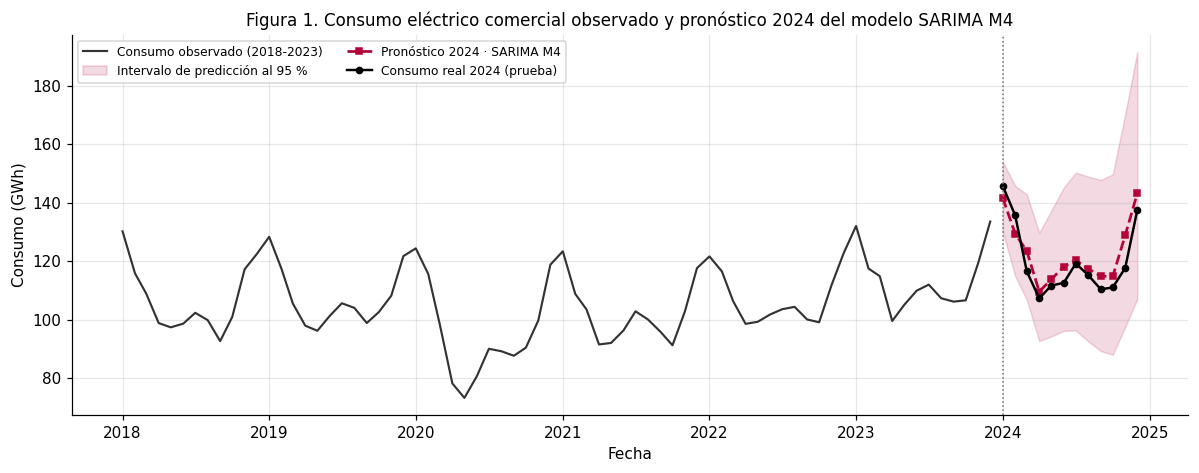

In [5]:
tabla_2023, pred23, inf23, sup23 = evaluar("2022-12", "2023-01", "2023-12")
tabla_2024, pred24, inf24, sup24 = evaluar("2023-12", "2024-01", "2024-12")
resumen = pd.concat({"Validación 2023": tabla_2023, "Prueba 2024": tabla_2024})

apertura = {
    "2024 no participa en el ajuste": modelo_final.nobs == 108 and modelo_final.fittedvalues.index.max() < pd.Timestamp("2024-01-01") and SELLO_2024,
    "modelo congelado antes de evaluar 2024":
        np.allclose(pred24, np.exp(CONGELADO["m"])) and np.allclose(sup24, np.exp(CONGELADO["m"] + 1.96 * CONGELADO["sd"]))
        and np.allclose(inf24, np.exp(CONGELADO["m"] - 1.96 * CONGELADO["sd"])) and huella(modelo_final.params, m24, sd24) == HUELLA_CONGELADO,
}
assert all(apertura.values())

real24 = test_final.to_numpy()
naive24, naive23 = y.shift(12)["2024-01":"2024-12"].to_numpy(), y.shift(12)["2023-01":"2023-12"].to_numpy()
assert np.array_equal(naive24, y["2023-01":"2023-12"].to_numpy()) and np.array_equal(naive23, y["2022-01":"2022-12"].to_numpy())
f24, n24 = tabla_2024.loc["Modelo final"], tabla_2024.loc["Naive estacional"]
f23, n23 = tabla_2023.loc["Modelo final"], tabla_2023.loc["Naive estacional"]
assert round(n23["RMSE"], 2) == S3["rmse_naive"] and round(n23["MAE"], 2) == S3["mae_naive"]
escala = lambda fin: float((y[:fin] - y[:fin].shift(12)).dropna().abs().mean())       # misma escala que `evaluar`
esc23, esc24 = escala("2022-12"), escala("2023-12")
mase_s3 = float(np.mean(np.abs(e_s3)) / esc23)
dentro = (real24 >= inf24) & (real24 <= sup24)
cob24, dentro24 = cobertura_y_ancho(real24, inf24, sup24), int(dentro.sum())
p_12de12, consumo_medio_24 = binom.pmf(12, 12, 0.95), real24.mean()
red_rmse24, red_mae24 = 100 * (1 - f24["RMSE"] / n24["RMSE"]), 100 * (1 - f24["MAE"] / n24["MAE"])
cob = lambda r, lo, hi: f"{int(((r >= lo) & (r <= hi)).sum())}/12"

maestra = pd.DataFrame([
    (MODELO, "Validación 2023", "media exp(m + s²/2) · S3", S3["rmse"], S3["mae"], mase_s3, S3["me"], f"{S3['cobertura']}/12"),
    (MODELO, "Validación 2023", "mediana exp(m) · plantilla", f23["RMSE"], f23["MAE"], f23["MASE"], np.mean(real_2023 - pred23), cob(real_2023, inf23, sup23)),
    ("Naive estacional", "Validación 2023", "mismo mes de 2022", S3["rmse_naive"], S3["mae_naive"], n23["MASE"], S3["me_naive"], "—"),
    (MODELO, "Prueba 2024", "mediana exp(m) · plantilla", f24["RMSE"], f24["MAE"], f24["MASE"], np.mean(real24 - pred24), cob(real24, inf24, sup24)),
    ("Naive estacional", "Prueba 2024", "mismo mes de 2023", n24["RMSE"], n24["MAE"], n24["MASE"], np.mean(real24 - naive24), "—"),
], columns=["Modelo", "Periodo", "Punto de pronóstico", "RMSE", "MAE", "MASE", "ME", "Cobertura IC95"]).set_index(["Modelo", "Periodo"])
display(maestra.style.format({"RMSE": "{:.2f}", "MAE": "{:.2f}", "MASE": "{:.3f}", "ME": "{:+.2f}"}, decimal=",")
        .set_caption("Tabla 3. SARIMA M4 y naive estacional en validación 2023 y prueba 2024 (GWh)"))
print(f"[OK] 2024 no participa en el ajuste | [OK] modelo congelado antes de evaluar 2024")
print(f"2024: RMSE −{red_rmse24:.1f} % y MAE −{red_mae24:.1f} % frente al naive | MAE = {100 * f24['MAE'] / consumo_medio_24:.1f} % del consumo "
      f"mensual medio | IC 95 %: {dentro24}/12, ancho medio {cob24['Ancho medio']:.2f} GWh | P(12 de 12 | IC calibrado) = {p_12de12:.2f}")

fig, ax = plt.subplots(figsize=(11, 4.4))
obs = y["2018-01":"2023-12"]
ax.plot(obs.index, obs, color="#333333", lw=1.4, label="Consumo observado (2018-2023)")
ax.fill_between(test_final.index, inf24, sup24, color=ROJO, alpha=0.15, label="Intervalo de predicción al 95 %")
ax.plot(test_final.index, pred24, color=ROJO, lw=1.8, ls="--", marker="s", ms=3.5, label=f"Pronóstico 2024 · {MODELO}")
ax.plot(test_final.index, real24, color="k", lw=1.6, marker="o", ms=4, label="Consumo real 2024 (prueba)")
ax.axvline(pd.Timestamp("2024-01-01"), color="#777777", ls=":", lw=1)
ax.set(xlabel="Fecha", ylabel="Consumo (GWh)", title="Figura 1. Consumo eléctrico comercial observado y pronóstico 2024 del modelo SARIMA M4")
ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); guardar(fig, "figura1_pronostico_2024.png"); plt.show()

Reestimado con 2015–2023, M4 obtiene **MASE = 0,71** en 2024 y supera al naive estacional (MASE = 1,02), con 34,7 % menos RMSE y 30,3 % menos MAE; su error medio equivale al 3,9 % del consumo mensual. Los 12 meses caen en el IC 95 % (ancho medio 50,70 GWh): con 12 meses, un intervalo calibrado cubre los 12 con probabilidad 0,54, por lo que el resultado es compatible con el 95 %, no una garantía.

La plantilla usa como punto la mediana exp(m); la S2 y la S3, la media exp(m + s²/2) (Hyndman y Athanasopoulos, 2021, sección 5.6). Es la misma especificación con distinto valor puntual: por eso 2023 aparece con RMSE de 4,12 (S3) y 4,78 GWh (plantilla). Las métricas de la S4 siguen la plantilla.

## 4. Seguimiento del sesgo

Retroalimentación de la S3: vigilar la subestimación de 2023 al reestimar con datos hasta 2023. El código compara 2023 con 2024 y determina si el sesgo persiste, disminuye o cambia de signo.

In [6]:
def sesgo(real, pred):
    e = np.asarray(real, float) - np.asarray(pred, float)
    return {"ME (GWh)": e.mean(), "Meses subestimados": int((e > 0).sum()), "Meses sobrestimados": int((e < 0).sum()),
            "Consumo anual real (GWh)": float(np.sum(real)), "Consumo anual pronosticado (GWh)": float(np.sum(pred)),
            "Diferencia anual (%)": 100 * (np.sum(pred) / np.sum(real) - 1)}

s23_s3, s23_pl, s24_pl = sesgo(real_2023, media_s3), sesgo(real_2023, pred23), sesgo(real24, pred24)
assert round(s23_s3["ME (GWh)"], 2) == S3["me"] and s23_s3["Meses subestimados"] == S3["subestimados"]
tabla_sesgo = pd.DataFrame({"2023 · media (S3)": s23_s3, "2023 · mediana (plantilla)": s23_pl, "2024 · mediana (plantilla)": s24_pl})
display(tabla_sesgo.style.format("{:.2f}", subset=pd.IndexSlice[["ME (GWh)"], :], decimal=",")
        .format("{:.0f}", subset=pd.IndexSlice[["Meses subestimados", "Meses sobrestimados"], :])
        .format("{:.1f}", subset=pd.IndexSlice[["Consumo anual real (GWh)", "Consumo anual pronosticado (GWh)", "Diferencia anual (%)"], :], decimal=",")
        .set_caption("Tabla 4. Sesgo de M4 en 2023 y 2024 (ME > 0 = subestimación)"))

me23, me24 = S3["me"], s24_pl["ME (GWh)"]
veredicto = "cambia de signo" if np.sign(me24) != np.sign(me23) else ("disminuye" if abs(me24) < abs(me23) else "persiste")
total = y.groupby(y.index.year).sum()
g23, g24, g24_pron = (100 * (total[2023] / total[2022] - 1), 100 * (total[2024] / total[2023] - 1), 100 * (pred24.sum() / total[2023] - 1))
print(f"Veredicto: la subestimación {veredicto.upper()} (ME {me23:+.2f} → {me24:+.2f} GWh) | crecimiento observado 2023 = {g23:+.1f} %, "
      f"2024 = {g24:+.1f} % | crecimiento 2024 proyectado por M4 = {g24_pron:+.1f} %")

,2023 · media (S3),2023 · mediana (plantilla),2024 · mediana (plantilla)
ME (GWh),"3,21","3,90","-2,92"
Meses subestimados,9,10,2
Meses sobrestimados,3,2,10
Consumo anual real (GWh),"1363,9","1363,9","1440,6"
Consumo anual pronosticado (GWh),"1325,4","1317,1","1475,6"
Diferencia anual (%),"-2,8","-3,4","2,4"


Veredicto: la subestimación CAMBIA DE SIGNO (ME +3.21 → -2.92 GWh) | crecimiento observado 2023 = +6.1 %, 2024 = +5.6 % | crecimiento 2024 proyectado por M4 = +8.2 %


**La subestimación cambia de signo**: de 9 de 12 meses subestimados en 2023 (ME = +3,21 GWh) a 10 de 12 sobrestimados en 2024 (ME = −2,92 GWh; +2,4 % anual). M4 incorporó el alza de 6,1 % de 2023 y proyectó +8,2 % para 2024, frente a +5,6 % observado. No se corrige el modelo con el error de 2024 (sería usar la prueba para ajustar); la sensibilidad del nivel se declara como limitación.

## 5. Sustento técnico acumulado S2–S4

Tabla 5. Cadena de evidencia (S2 y S3: cifras recuperadas de sus notebooks; S4: esta ejecución).

| Etapa | Evidencia | Decisión |
|---|---|---|
| S2 · Transformación y órdenes | Box-Cox λ̂ = 0,004; con ∇∇₁₂, ADF p < 0,001 y KPSS p ≥ 0,10; d = 2 sobrediferencia (ρ1 = −0,425) (Dickey y Fuller, 1979; Kwiatkowski et al., 1992) | log, d = 1, D = 1, s = 12 |
| S2 · Selección | RMSE / MAE 2023 (GWh): M4 4,12 / 3,71; M1 7,20 / 6,71 (menor AIC, −300,0); M6 5,71 / 5,20; naive 7,26 / 6,53 | SARIMA M4 (prima el error fuera de muestra; Box et al., 2016) |
| S2 · Residuos | Ljung-Box p = 0,679 (K = 12) y 0,059 (K = 24); Jarque-Bera p = 0,564 (Ljung y Box, 1978) | M4 utilizable con reservas |
| S3 · Memoria larga | H = 0,584, compatible con ruido blanco (n = 83); ARFIMA: RMSE 4,19 GWh (Granger y Joyeux, 1980) | Descartar ARFIMA |
| S3 · Volatilidad | Ljung-Box de residuos² p = 0,829; ARCH-LM p = 0,786; GARCH no cambia la cobertura (Bollerslev, 1986) | Descartar GARCH |
| S4 · Prueba 2024 | MASE = 0,71 (naive 1,02); cobertura 12/12 | Mantener M4 |

## 6. Selección final y recomendación

**Modelo final.** M4 = SARIMA(0,1,0)(1,1,0)₁₂ sobre log(consumo): es el único candidato que superó al naive en la validación 2023 y lo vuelve a superar en la prueba 2024, con un solo coeficiente y sin componentes cuyo aporte no se haya demostrado.

**Recomendación operativa.** Contratar mes a mes por sobre la mediana pronosticada, porque quedarse corto cuesta más que sobrar (c_u > c_o ⇒ τ* > 0,5). El cuantil óptimo τ* = c_u / (c_u + c_o) **no puede calcularse**: los documentos del curso no entregan valores numéricos de c_u ni c_o. El pronóstico de 2025 se presenta en el Anexo. Además, reestimar cada diciembre y vigilar el sesgo.

## 7. Limitaciones

- **Prueba de 12 meses:** el MASE y la cobertura provienen de un solo año y un solo origen de pronóstico.
- **COVID-19 en el ajuste:** 22 meses con `covid` = 1; el mayor residuo sigue siendo 2020-04 (3,4 s), lo que puede ensanchar los intervalos.
- **Rezago 24:** ρ24 = −0,31 sigue fuera de ±0,201: la estructura bianual no queda capturada del todo.
- **Cambio de signo del sesgo:** −2,8 % en 2023 y +2,4 % en 2024; el nivel del pronóstico depende del último año incorporado.

## 8. Conclusiones

1. **M4 supera al naive estacional en 2024:** MASE = 0,71 frente a 1,02, con RMSE de 5,35 frente a 8,19 GWh.
2. **El sesgo de 2023 no persistió, cambió de signo:** de 9/12 meses subestimados (ME = +3,21 GWh) a 10/12 sobrestimados (ME = −2,92 GWh).
3. **Incertidumbre:** el error absoluto medio fue de 4,65 GWh (3,9 % del consumo mensual medio) y el intervalo de predicción al 95 % cubrió los 12 meses observados de 2024, aunque este resultado debe interpretarse con cautela debido al tamaño reducido del conjunto de prueba.
4. **M4 se mantiene como modelo final.** Dado que el costo de contratar menos energía es mayor que el costo de contratar en exceso, el volumen de contratación debe ubicarse sobre la mediana pronosticada; el cuantil exacto requiere conocer la relación entre los costos de déficit y excedente de DEL.

### Anexo opcional: extensión operativa 2025

Cerrada la evaluación, M4 se reestima con 2015–2024 sin cambiar su especificación para pronosticar 2025, que no tiene datos reales para evaluarse. La tabla muestra el volumen que implicaría cada cuantil τ (suma de cuantiles mensuales); no recomienda un τ, que depende solo de los costos.

In [7]:
assert {"tabla_2024", "maestra", "tabla_sesgo"} <= set(globals()), "la evaluación 2024 debe cerrarse antes"
modelo_op = SARIMAX(log_y, order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
assert modelo_op.mle_retvals.get("converged", True) and modelo_op.nobs == 120 and tuple(modelo_op.model.order) == ORDEN
p25 = modelo_op.get_forecast(12)
m25 = p25.predicted_mean
sd25 = (p25.conf_int(alpha=0.05).iloc[:, 1] - m25) / 1.96
total25_med, total25_media = float(np.exp(m25).sum()), float(np.exp(m25 + sd25 ** 2 / 2).sum())

COSTO_DEFICIT = None      # c_u: costo por GWh contratado de menos. No disponible: no se inventa
COSTO_EXCEDENTE = None    # c_o: costo por GWh contratado de más. No disponible: no se inventa
TAU = COSTO_DEFICIT / (COSTO_DEFICIT + COSTO_EXCEDENTE) if COSTO_DEFICIT is not None and COSTO_EXCEDENTE is not None else None

TAUS = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
tabla_tau = pd.DataFrame({"Volumen 2025 (GWh)": [float(np.exp(m25 + norm.ppf(t) * sd25).sum()) for t in TAUS]}, index=pd.Index(TAUS, name="τ"))
tabla_tau["Sobre la mediana (%)"] = 100 * (tabla_tau["Volumen 2025 (GWh)"] / total25_med - 1)
volumen_tau = tabla_tau["Volumen 2025 (GWh)"]
display(tabla_tau.T.style.format("{:.1f}", decimal=",").format_index("{:.2f}", axis=1, decimal=",")
        .set_caption("Tabla 6. Volumen 2025 según el cuantil τ de la distribución predictiva de M4 (reestimado con 2015-2024)"))
print(f"2025: mediana = {total25_med:.1f} GWh | media = {total25_media:.1f} GWh | variación frente a 2024 = {100 * (total25_med / total[2024] - 1):+.1f} % | "
      + (f"τ* = {TAU:.3f} → {np.exp(m25 + norm.ppf(TAU) * sd25).sum():.1f} GWh" if TAU is not None
         else "τ* no calculable: faltan c_u y c_o (solo se sabe que τ* > 0,5)"))

τ,"0,50","0,60","0,70","0,80","0,90","0,95"
Volumen 2025 (GWh),"1500,3","1540,2","1584,2","1637,5","1714,6","1781,4"
Sobre la mediana (%),"0,0","2,7","5,6","9,1","14,3","18,7"


2025: mediana = 1500.3 GWh | media = 1509.2 GWh | variación frente a 2024 = +4.1 % | τ* no calculable: faltan c_u y c_o (solo se sabe que τ* > 0,5)


## Control de reproducibilidad

In [8]:
# Cifras citadas en el texto frente a esta ejecución, al número de decimales del texto
CITADAS = {
    "Φ1 S4": (phi_s4, -0.359, 3), "ee Φ1": (se_phi, 0.094, 3), "ΔΦ1 en ee": (abs(phi_s4 - S3["phi"]) / se_phi, 0.5, 1),
    "AIC S4": (modelo_final.aic, -322.9, 1), "ρ24": (acf_final[24], -0.31, 2), "banda ACF": (banda_final, 0.201, 3),
    "Ljung-Box K = 24": (lb_final.lb_pvalue.iloc[1], 0.185, 3), "mayor residuo (s)": (z_final.max(), 3.4, 1),
    "meses covid en el ajuste": (int(df.loc[:"2023-12", "covid"].sum()), 22, 0),
    "RMSE 2024": (f24["RMSE"], 5.35, 2), "MAE 2024": (f24["MAE"], 4.65, 2), "MASE 2024": (f24["MASE"], 0.71, 2),
    "RMSE naive 2024": (n24["RMSE"], 8.19, 2), "MASE naive 2024": (n24["MASE"], 1.02, 2),
    "reducción RMSE (%)": (red_rmse24, 34.7, 1), "reducción MAE (%)": (red_mae24, 30.3, 1),
    "MAE / consumo medio (%)": (100 * f24["MAE"] / consumo_medio_24, 3.9, 1), "RMSE 2023 plantilla": (f23["RMSE"], 4.78, 2),
    "cobertura 2024": (dentro24, 12, 0), "ancho medio 2024": (cob24["Ancho medio"], 50.70, 2), "P(12 de 12)": (p_12de12, 0.54, 2),
    "ME 2024": (me24, -2.92, 2), "sobrestimados 2024": (s24_pl["Meses sobrestimados"], 10, 0),
    "diferencia anual 2024 (%)": (s24_pl["Diferencia anual (%)"], 2.4, 1),
    "crecimiento 2023": (g23, 6.1, 1), "crecimiento 2024": (g24, 5.6, 1), "crecimiento 2024 en M4": (g24_pron, 8.2, 1),
    "mediana 2025": (total25_med, 1500.3, 1),
}
distintas = {k: (f"{float(v):.{dec}f}", f"{c:.{dec}f}") for k, (v, c, dec) in CITADAS.items() if f"{float(v):.{dec}f}" != f"{c:.{dec}f}"}

# Declaración de IA: última celda e idéntica a la de la Sumativa 3
IA_SHA256 = "61d6676261c85841bfd70b7fbb35263633db797c6aebc9f16d3b64da0935592c"
ruta_nb = next((p for p in (Path("mcdi505_S4calarcon.ipynb"), Path("notebooks/semana_4/S4/mcdi505_S4calarcon.ipynb")) if p.exists()), None)
ia_ok = None
if ruta_nb is not None:
    ultima = json.loads(ruta_nb.read_text(encoding="utf-8"))["cells"][-1]
    ia_ok = ultima["cell_type"] == "markdown" and hashlib.sha256("".join(ultima["source"]).encode("utf-8")).hexdigest() == IA_SHA256

comprobaciones = {
    "120 meses (2015-01 a 2024-12), frecuencia MS, sin duplicados ni faltantes":
        len(y) == 120 and y.index.freqstr == "MS" and not y.index.duplicated().any() and y.notna().all(),
    "modelo M4 = SARIMA(0,1,0)(1,1,0,12), sin exógenas, ARFIMA ni GARCH":
        tuple(modelo_final.model.order) == (0, 1, 0) and tuple(modelo_final.model.seasonal_order) == (1, 1, 0, 12)
        and modelo_final.model.k_exog == 0 and D_FRACCIONAL is None and not BANDAS_GARCH,
    "train 2015-2023 (108) y test 2024 (12)": len(train_final) == 108 and len(test_final) == 12,
    "2024 no usado en el ajuste y modelo congelado antes de evaluarlo": all(apertura.values()),
    "naive correcto (mismo mes del año anterior)":
        np.array_equal(naive24, y["2023-01":"2023-12"].to_numpy()) and np.array_equal(naive23, y["2022-01":"2022-12"].to_numpy()),
    "RMSE, MAE y MASE correctos (recalculados)":
        np.isclose(f24["RMSE"], np.sqrt(np.mean((real24 - pred24) ** 2))) and np.isclose(f24["MAE"], np.mean(np.abs(real24 - pred24)))
        and np.isclose(f24["MASE"], np.mean(np.abs(real24 - pred24)) / esc24) and np.isclose(n24["MASE"], np.mean(np.abs(real24 - naive24)) / esc24),
    "cobertura correcta": np.isclose(f24["Cobertura IC 95 %"], dentro.mean()),
    "cifras heredadas de la S3 reproducidas": all(continuidad.values()),
    f"cifras de texto = outputs ({len(CITADAS)})": not distintas,
    "notebook ejecuta sin errores (todas las secciones llegaron a este control)":
        all(v in globals() for v in ("df", "modelo_final", "maestra", "tabla_sesgo", "tabla_tau", "lb_final")),
}
if distintas:
    print("Cifras del texto que difieren de esta ejecución (calculada, citada):", distintas)
for nombre, ok in comprobaciones.items():
    print(f"[{'OK' if ok else 'FALLA'}] {nombre}")
print("[OK] declaración IA intacta" if ia_ok else "[FALLA] declaración IA modificada" if ia_ok is False
      else "[--] declaración IA: no verificable en este entorno")
assert all(comprobaciones.values()) and ia_ok is not False

[OK] 120 meses (2015-01 a 2024-12), frecuencia MS, sin duplicados ni faltantes
[OK] modelo M4 = SARIMA(0,1,0)(1,1,0,12), sin exógenas, ARFIMA ni GARCH
[OK] train 2015-2023 (108) y test 2024 (12)
[OK] 2024 no usado en el ajuste y modelo congelado antes de evaluarlo
[OK] naive correcto (mismo mes del año anterior)
[OK] RMSE, MAE y MASE correctos (recalculados)
[OK] cobertura correcta
[OK] cifras heredadas de la S3 reproducidas
[OK] cifras de texto = outputs (28)
[OK] notebook ejecuta sin errores (todas las secciones llegaron a este control)
[OK] declaración IA intacta


## 9. Referencias

Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, *31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., y Ljung, G. M. (2016). *Time series analysis: Forecasting and control* (5.ª ed.). Wiley.

Dickey, D. A., y Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association*, *74*(366a), 427–431. https://doi.org/10.1080/01621459.1979.10482531

Granger, C. W. J., y Joyeux, R. (1980). An introduction to long-memory time series models and fractional differencing. *Journal of Time Series Analysis*, *1*(1), 15–29. https://doi.org/10.1111/j.1467-9892.1980.tb00297.x

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Hyndman, R. J., y Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting*, *22*(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001

Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., y Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root. *Journal of Econometrics*, *54*(1–3), 159–178. https://doi.org/10.1016/0304-4076(92)90104-Y

Ljung, G. M., y Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika*, *65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Seabold, S., y Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Universidad Andrés Bello. (s. f.-a). *MCDI505 — Análisis de series de tiempo. Caso transversal del curso: Documento base* [Notebook de Jupyter]. Material docente del curso, Magíster en Ciencia de Datos e Inteligencia Artificial.

Universidad Andrés Bello. (s. f.-b). *MCDI505 — Semana 4: Evaluación final en 2024 (anexo del informe)* [Plantilla de notebook de Jupyter `mcdi505_s4_plantilla.ipynb`]. Material docente del curso, Magíster en Ciencia de Datos e Inteligencia Artificial.

## Declaración de uso de Inteligencia Artificial

| Pregunta | Respuesta |
|---|---|
| ¿Utilizó herramientas de inteligencia artificial en esta entrega? | Sí. Se utilizaron herramientas de inteligencia artificial como apoyo durante el desarrollo y revisión de la entrega. |
| ¿Para qué se utilizaron? | Se utilizaron para apoyar la organización de ideas, revisar la coherencia del análisis, detectar posibles omisiones y mejorar la redacción académica del notebook. |
| ¿Cómo se verificaron sus aportes? | Los aportes fueron contrastados con los resultados obtenidos mediante la ejecución del notebook, las instrucciones y guía de la asignatura, la bibliografía utilizada y los controles de reproducibilidad implementados. |

Los resultados numéricos y las decisiones metodológicas se sustentan en la ejecución del código y en la evidencia obtenida durante el análisis.